In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder,LabelEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report

In [2]:
file_path="customer_churn_dataset.csv"
with open(file_path,"r") as file:
    df=pd.read_csv(file)

In [3]:
df.head()

,customer_id,age,tenure_months,monthly_charges,total_charges,support_calls,contract_type,payment_method,internet_service,streaming,auto_pay,tech_support,satisfaction_score,monthly_usage_gb,churn
0,CUST0630,37,10,885.58,8168.54,3,Month-to-month,Cash,DSL,No,No,No,4.0,22.8,Yes
1,CUST0789,46,35,1577.43,62414.26,0,One year,Debit card,Fiber,No,Yes,No,5.0,47.3,No
2,CUST0685,26,26,432.66,10524.64,4,One year,Credit card,NaN,No,Yes,Yes,5.0,24.1,No
3,CUST0517,63,35,421.62,13188.80,3,One year,UPI,Fiber,No,No,Yes,3.0,69.6,Yes
4,CUST0530,65,67,673.82,46924.05,1,Month-to-month,UPI,DSL,Yes,Yes,Yes,1.0,50.8,No


In [4]:
df.info

<bound method DataFrame.info of      customer_id  age  tenure_months  monthly_charges  total_charges  \
0       CUST0630   37             10           885.58        8168.54   
1       CUST0789   46             35          1577.43       62414.26   
2       CUST0685   26             26           432.66       10524.64   
3       CUST0517   63             35           421.62       13188.80   
4       CUST0530   65             67           673.82       46924.05   
...          ...  ...            ...              ...            ...   
1005    CUST0107   58             18           429.34        8223.31   
1006    CUST0271   33             27          1754.87            NaN   
1007    CUST0861   68             54          1152.79       60652.57   
1008    CUST0436   24              8          1762.39       16031.99   
1009    CUST0103   59             67          1486.14      108740.24   

      support_calls   contract_type payment_method internet_service streaming  \
0                 3  M

In [5]:
df.columns

Index(['customer_id', 'age', 'tenure_months', 'monthly_charges',
       'total_charges', 'support_calls', 'contract_type', 'payment_method',
       'internet_service', 'streaming', 'auto_pay', 'tech_support',
       'satisfaction_score', 'monthly_usage_gb', 'churn'],
      dtype='str')

In [6]:
df.shape

(1010, 15)

In [7]:
df.isna().sum()

customer_id             0
age                     0
tenure_months           0
monthly_charges        25
total_charges          30
support_calls           0
contract_type           0
payment_method         20
internet_service      169
streaming               0
auto_pay                0
tech_support            0
satisfaction_score     20
monthly_usage_gb        0
churn                   0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(10)

In [9]:
df.drop_duplicates(inplace=True)

In [10]:
df['churn'].value_counts()

churn
No     661
Yes    339
Name: count, dtype: int64

In [11]:
df.groupby('contract_type')['churn'].value_counts()

contract_type   churn
1 year          No         3
                Yes        1
Month to month  Yes        2
                No         1
Month-to-month  No       326
                Yes      218
One year        No       190
                Yes       95
Two year        No       141
                Yes       23
Name: count, dtype: int64

In [12]:
df['contract_type']=df['contract_type'].replace({
    'Month to month':'Month-to-month','1 year':'One Year','One year':'One Year'})

In [13]:
df.groupby('payment_method')['churn'].value_counts()

payment_method  churn
Bank Transfer   Yes        1
Bank transfer   No       127
                Yes       62
Cash            No       127
                Yes       65
Credit Card     No         1
Credit card     No       136
                Yes       67
Debit card      No       128
                Yes       71
UPI             No       132
                Yes       63
Name: count, dtype: int64

In [14]:
df['payment_method']=df['payment_method'].replace({
    'Bank transfer':'Bank Transfer','Credit card':'Credit Card'})

In [15]:
df.groupby('churn')[["age",
    "tenure_months",
    "monthly_charges",
    "total_charges",
    "support_calls",
    "satisfaction_score",
    "monthly_usage_gb"]].mean()

,age,tenure_months,monthly_charges,total_charges,support_calls,satisfaction_score,monthly_usage_gb
churn,,,,,,,
No,43.821483,38.588502,1006.757981,39161.069969,2.036309,3.236476,82.017549
Yes,43.294985,31.731563,1097.370242,34679.454632,2.297935,2.600601,77.320059


In [16]:
df.groupby('internet_service')['churn'].value_counts()

internet_service  churn
DSL               No       264
                  Yes       99
Fiber             No       288
                  Yes      182
Name: count, dtype: int64

In [17]:
df.groupby(['streaming'])['churn'].value_counts()

streaming  churn
No         No       301
           Yes      153
Yes        No       354
           Yes      184
no         No         3
yes        No         3
           Yes        2
Name: count, dtype: int64

In [18]:
df['streaming']=df['streaming'].replace({
    'yes':'Yes','no':'No'})

In [19]:
df.groupby(['auto_pay'])['churn'].value_counts()

auto_pay  churn
No        No       234
          Yes      150
Yes       No       427
          Yes      189
Name: count, dtype: int64

In [20]:
df.groupby(['tech_support'])['churn'].value_counts()

tech_support  churn
No            No       356
              Yes      190
Yes           No       305
              Yes      149
Name: count, dtype: int64

In [21]:
X=df.drop(['churn','customer_id'],axis=1)

In [22]:
X.select_dtypes(include=['int64','float64']).columns.tolist()

['age',
 'tenure_months',
 'monthly_charges',
 'total_charges',
 'support_calls',
 'satisfaction_score',
 'monthly_usage_gb']

In [23]:
numerical_cols=['age', 'tenure_months', 'monthly_charges', 'total_charges', 'support_calls', 'satisfaction_score', 'monthly_usage_gb']
categorical_cols=['contract_type','payment_method','internet_service','streaming','auto_pay','tech_support']

In [24]:
for col in categorical_cols:
    print(f"\n{col}")
    print(
        df.groupby(col)["churn"]
          .apply(lambda x: (x == "Yes").mean())
          .sort_values(ascending=False)
    )


contract_type
contract_type
Month-to-month    0.402194
One Year          0.332180
Two year          0.140244
Name: churn, dtype: float64

payment_method
payment_method
Debit card       0.356784
Cash             0.338542
Bank Transfer    0.331579
Credit Card      0.328431
UPI              0.323077
Name: churn, dtype: float64

internet_service
internet_service
Fiber    0.387234
DSL      0.272727
Name: churn, dtype: float64

streaming
streaming
Yes    0.342541
No     0.334792
Name: churn, dtype: float64

auto_pay
auto_pay
No     0.390625
Yes    0.306818
Name: churn, dtype: float64

tech_support
tech_support
No     0.347985
Yes    0.328194
Name: churn, dtype: float64


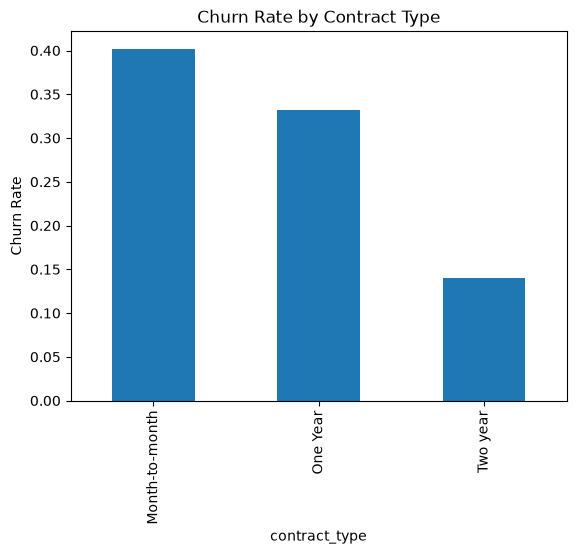

In [25]:
df.groupby("contract_type")["churn"].apply(
    lambda x: (x == "Yes").mean()
).plot(kind="bar")

plt.ylabel("Churn Rate")
plt.title("Churn Rate by Contract Type")
plt.show()

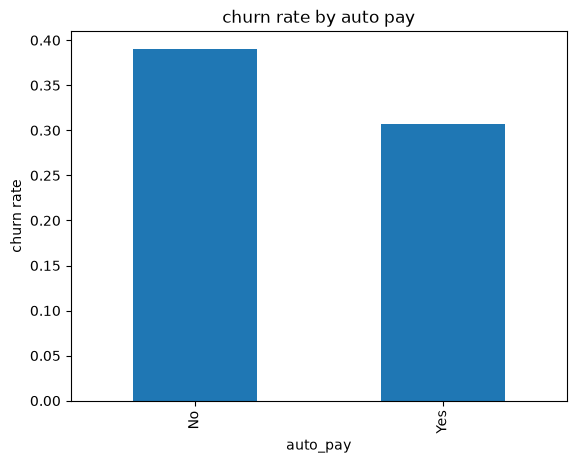

In [26]:
df.groupby('auto_pay')['churn'].apply(lambda x:(x=='Yes').mean()).plot(kind="bar")
plt.ylabel('churn rate')
plt.title('churn rate by auto pay')
plt.show()

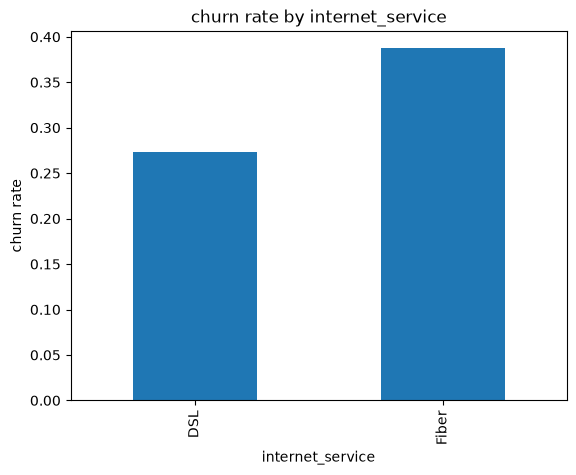

In [27]:
df.groupby('internet_service')['churn'].apply(
    lambda x:(x=='Yes').mean()).plot(kind='bar')
plt.ylabel('churn rate')
plt.title('churn rate by internet_service')
plt.show()

In [28]:
numerical_pipeline=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler())])

nominal_pipeline=Pipeline([
    ('imputer',SimpleImputer(strategy="constant", fill_value="Missing")),
    ('onehot',OneHotEncoder(sparse_output=False,handle_unknown="ignore"))])

In [29]:
df["internet_service"].value_counts(dropna=False)

internet_service
Fiber    470
DSL      363
NaN      167
Name: count, dtype: int64

In [30]:
df.groupby("internet_service", dropna=False)["churn"].apply(
    lambda x: (x == "Yes").mean()
)

internet_service
DSL      0.272727
Fiber    0.387234
NaN      0.347305
Name: churn, dtype: float64

In [31]:
preprocessor=ColumnTransformer(transformers=[
    ('numerical',numerical_pipeline,numerical_cols),
    ('nominal',nominal_pipeline,categorical_cols)])

In [32]:
y=df['churn']
le=LabelEncoder()
y=le.fit_transform(y);

In [33]:
y[:10]

array([1, 0, 0, 1, 0, 0, 0, 0, 0, 0])

In [34]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [35]:
from sklearn.ensemble import RandomForestClassifier

In [36]:
rf_pipeline=Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('model',RandomForestClassifier(n_estimators=100,random_state=42))])

In [37]:
rf_pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['age','tenure_months','monthly_charges',...,'tech_support', 'satisfaction_score','monthly_usage_gb']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('nominal', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By spec

In [38]:
y_preds_rf=rf_pipeline.predict(X_test)
y_preds_rf[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [39]:
np.array(y_test[:10])

array([0, 0, 0, 0, 0, 0, 1, 0, 0, 0])

In [40]:
Accuracy=accuracy_score(y_test,y_preds_rf)
Precision=precision_score(y_test,y_preds_rf)
Recall=recall_score(y_test,y_preds_rf)
F1=f1_score(y_test,y_preds_rf)
ConfusionMatrix=confusion_matrix(y_test,y_preds_rf)

In [41]:
print(f"Accuracy Score:{Accuracy}")
print(f"Precision Score:{Precision}")
print(f"Recall Score:{Recall}")
print(f"F1 Score:{F1}")
print(f"Confusion Matrix:{ConfusionMatrix}")

Accuracy Score:0.645
Precision Score:0.4444444444444444
Recall Score:0.17647058823529413
F1 Score:0.25263157894736843
Confusion Matrix:[[117  15]
 [ 56  12]]


In [42]:
rf_pipeline.score(X_test,y_test)

0.645

In [43]:
from sklearn.linear_model import LogisticRegression

In [56]:
lr_pipeline=Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('model',LogisticRegression(class_weight="balanced",random_state=42,max_iter=1000,))])

In [57]:
lr_pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['age','tenure_months','monthly_charges',...,'tech_support', 'satisfaction_score','monthly_usage_gb']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('nominal', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By spec

In [58]:
lr_pipeline.score(X_test,y_test)

0.69

In [59]:
y_preds_lr=lr_pipeline.predict(X_test)
y_preds_lr[:10]

array([0, 0, 0, 0, 0, 0, 1, 1, 0, 0])

In [60]:
Accuracy=accuracy_score(y_test,y_preds_lr)
Precision=precision_score(y_test,y_preds_lr)
Recall=recall_score(y_test,y_preds_lr)
F1=f1_score(y_test,y_preds_lr)
ConfusionMatrix=confusion_matrix(y_test,y_preds_lr)

In [61]:
print(f"Accuracy Score:{Accuracy}")
print(f"Precision Score:{Precision}")
print(f"Recall Score:{Recall}")
print(f"F1 Score:{F1}")
print(f"Confusion Matrix:{ConfusionMatrix}")

Accuracy Score:0.69
Precision Score:0.5375
Recall Score:0.6323529411764706
F1 Score:0.581081081081081
Confusion Matrix:[[95 37]
 [25 43]]


In [62]:
rf_class=classification_report(y_test,y_preds_rf)
lr_class=classification_report(y_test,y_preds_lr)

In [63]:
print(f"ClassificationReport:{rf_class}")
print(f"Classification report for logistic regression:{lr_class}")

ClassificationReport:              precision    recall  f1-score   support

           0       0.68      0.89      0.77       132
           1       0.44      0.18      0.25        68

    accuracy                           0.65       200
   macro avg       0.56      0.53      0.51       200
weighted avg       0.60      0.65      0.59       200

Classification report for logistic regression:              precision    recall  f1-score   support

           0       0.79      0.72      0.75       132
           1       0.54      0.63      0.58        68

    accuracy                           0.69       200
   macro avg       0.66      0.68      0.67       200
weighted avg       0.71      0.69      0.70       200



In [65]:
from sklearn.metrics import roc_auc_score

rf_prob = rf_pipeline.predict_proba(X_test)[:, 1]
lr_prob = lr_pipeline.predict_proba(X_test)[:, 1]

print("Random Forest ROC-AUC:", roc_auc_score(y_test, rf_prob))
print("Logistic Regression ROC-AUC:", roc_auc_score(y_test, lr_prob))

Random Forest ROC-AUC: 0.7023729946524064
Logistic Regression ROC-AUC: 0.7579099821746881


In [66]:
print(np.array_equal(rf_prob, lr_prob))

False


In [67]:
lr_prob = lr_pipeline.predict_proba(X_test)[:, 1]
lr_prob

array([0.07405635, 0.32557282, 0.40086558, 0.43152407, 0.24660646,
       0.36185026, 0.53845426, 0.59987589, 0.4127821 , 0.30328867,
       0.23224254, 0.46714721, 0.47639194, 0.44298513, 0.41866508,
       0.17518423, 0.25738829, 0.17884321, 0.65220268, 0.56168675,
       0.63204241, 0.13808492, 0.40355133, 0.26702604, 0.26126475,
       0.71548545, 0.17095331, 0.56122224, 0.70572305, 0.56291685,
       0.68741152, 0.34571587, 0.45097819, 0.64382831, 0.21649679,
       0.36319492, 0.30311359, 0.52253373, 0.29509261, 0.50857436,
       0.39514438, 0.54961634, 0.27459463, 0.43195953, 0.23513228,
       0.15292244, 0.13202576, 0.35484782, 0.1850136 , 0.45702128,
       0.14112869, 0.41752578, 0.55889447, 0.38882978, 0.13662335,
       0.36268953, 0.43318858, 0.36465849, 0.5511111 , 0.75080525,
       0.85676774, 0.40174626, 0.32725909, 0.44663349, 0.519195  ,
       0.4462855 , 0.53251406, 0.69329734, 0.70336541, 0.54525464,
       0.69196122, 0.42607734, 0.26032963, 0.87018901, 0.56422

In [76]:
thresholds = [0.25, 0.35, 0.45, 0.55, 0.65, 0.75]

for threshold in thresholds:

    y_pred_threshold = np.where(
        lr_prob >= threshold,
        1,
        0
    )

    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)

    print(f"Threshold: {threshold}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall:    {recall:.3f}")
    print(f"F1:        {f1:.3f}")
    print("-" * 30)

Threshold: 0.25
Precision: 0.402
Recall:    0.971
F1:        0.569
------------------------------
Threshold: 0.35
Precision: 0.464
Recall:    0.941
F1:        0.621
------------------------------
Threshold: 0.45
Precision: 0.520
Recall:    0.765
F1:        0.619
------------------------------
Threshold: 0.55
Precision: 0.565
Recall:    0.515
F1:        0.538
------------------------------
Threshold: 0.65
Precision: 0.625
Recall:    0.294
F1:        0.400
------------------------------
Threshold: 0.75
Precision: 0.600
Recall:    0.132
F1:        0.217
------------------------------


In [77]:
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"]
}

In [78]:
from sklearn.model_selection import GridSearchCV

In [79]:
grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

In [80]:
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__class_weight': [None, 'balanced']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of

In [81]:
print("Best parameters:", grid_search.best_params_)
print("Best CV F1:", grid_search.best_score_)

Best parameters: {'model__C': 1, 'model__class_weight': 'balanced'}
Best CV F1: 0.5827371871870843


In [82]:
best_lr_pipeline = grid_search.best_estimator_

In [83]:
y_pred_tuned = best_lr_pipeline.predict(X_test)

print(classification_report(y_test, y_pred_tuned))

              precision    recall  f1-score   support

           0       0.79      0.72      0.75       132
           1       0.54      0.63      0.58        68

    accuracy                           0.69       200
   macro avg       0.66      0.68      0.67       200
weighted avg       0.71      0.69      0.70       200



In [84]:
y_prob_tuned = best_lr_pipeline.predict_proba(X_test)[:, 1]

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_prob_tuned)
)

ROC-AUC: 0.7579099821746881


In [85]:
import joblib

joblib.dump(best_lr_pipeline, "customer_churn_pipeline.pkl")
joblib.dump(0.45, "churn_threshold.pkl")

['churn_threshold.pkl']

In [86]:
def predict_churn(customer):
    customer_df = pd.DataFrame([customer])

    probability = best_lr_pipeline.predict_proba(customer_df)[0, 1]
    threshold = joblib.load("churn_threshold.pkl")

    if probability >= threshold:
        prediction = "Yes"
    else:
        prediction = "No"

    return prediction, probability

In [87]:
new_customer = {
    "age": 25,
    "tenure_months": 5,
    "monthly_charges": 1400,
    "total_charges": 7000,
    "support_calls": 5,
    "contract_type": "Month-to-month",
    "payment_method": "Credit card",
    "internet_service": "Fiber",
    "streaming": "Yes",
    "auto_pay": "No",
    "tech_support": "No",
    "satisfaction_score": 2,
    "monthly_usage_gb": 60
}

In [88]:
prediction, probability = predict_churn(new_customer)

print("Prediction:", prediction)
print(f"Churn Probability: {probability:.2%}")

Prediction: Yes
Churn Probability: 90.68%


In [89]:
customer_2 = {
    "age": 45,
    "tenure_months": 60,
    "monthly_charges": 600,
    "total_charges": 36000,
    "support_calls": 1,
    "contract_type": "Two year",
    "payment_method": "UPI",
    "internet_service": "DSL",
    "streaming": "No",
    "auto_pay": "Yes",
    "tech_support": "Yes",
    "satisfaction_score": 5,
    "monthly_usage_gb": 80
}

In [90]:
prediction, probability = predict_churn(customer_2)

print("Prediction:", prediction)
print(f"Churn Probability: {probability:.2%}")

Prediction: No
Churn Probability: 3.58%
